# Sequential ray tracing to OPD maps

`pyoptics.raytrace` traces rays exactly through systems of spherical, conic and aspheric surfaces (lenses and
mirrors, also decentred and tilted) and turns the result into wave optics: the optical path difference
(OPD) over the pupil, its Fringe Zernike coefficients, and the PSF, MTF and Strehl ratio from
`pyoptics.imaging`. Paraxial quantities and Seidel sums come from a paraxial y-nu trace that is
cross-checked against `pyoptics.abcd`.

**Conventions** (see the module docstring):

- Light enters in +z, the first vertex is at z = 0, the field lies in the y-z plane.
- Radii R > 0 if the centre of curvature lies in +z (as in `abcd`). Thicknesses are signed z distances
  to the next vertex; behind a mirror they are negative.
- Sag: z(r) = c r²/(1 + √(1 − (1+K) c² r²)) + A₄ r⁴ + A₆ r⁶ + …
- Field: the angle of incidence in radians for an object at infinity, the object height otherwise. Pairs
  (x, y) give fields in any direction.
- Surfaces can be decentred and tilted, and `CoordinateBreak` changes the axis (section 5).
- Pupil coordinates (P_x, P_y) are normalized entrance pupil coordinates. With ray aiming, (P_x, P_y)
  hits the stop at (P_x, P_y) × its semi diameter.
- **OPD = OPL_ray − OPL_chief** on a reference sphere centred on the chief ray's image point, so the pupil
  phase is **+2π·OPD/λ**, the same as the propagators' exp(+ik_z z). An image plane behind the focus gives
  OPD < 0 at the pupil rim. A lens with undercorrected spherical aberration (marginal rays focus short)
  also has OPD < 0 at the rim.

Lengths are in mm here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import abcd
from pyoptics.analytical import airy_pattern
from pyoptics.utils import grid1d

plt.rcParams["figure.dpi"] = 100
WL = 587.5618e-6            # d line in mm
BK7 = (1.5168, 64.17)       # (n_d, V_d) for materials.abbe_dispersion
F2 = (1.6200, 36.37)


def show_opd(ax, m, title="", vmax=None):
    vmax = np.nanmax(np.abs(m.W)) if vmax is None else vmax
    im = ax.imshow(m.W, extent=[-1, 1, -1, 1], origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("$P_x$")
    ax.set_ylabel("$P_y$")
    plt.colorbar(im, ax=ax, label="OPD [waves]", shrink=0.8)

## 1 A plano-convex lens: which way round?

A plano-convex BK7 lens with f ≈ 100 mm at f/5. The stop sits at the first surface and the image plane at
the paraxial focus. With the curved side towards the collimated beam, both surfaces share the refraction.
Turned around, the plane side does nothing and the curved side does all the bending, which causes much more
spherical aberration.

System(wavelength=0.0005875618, stop_index=0, object_distance=inf, max_field=0.03490658503988659)
   0* Surface(R=51.67999999999999, thickness=5.0, n_after=None, material=(1.5168, 64.17), conic=0.0, aspheric=(), semi_diameter=10.0) n'=1.516800
   1  Surface(R=inf, thickness=96.70358649789033, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=10.5) n'=1.000000


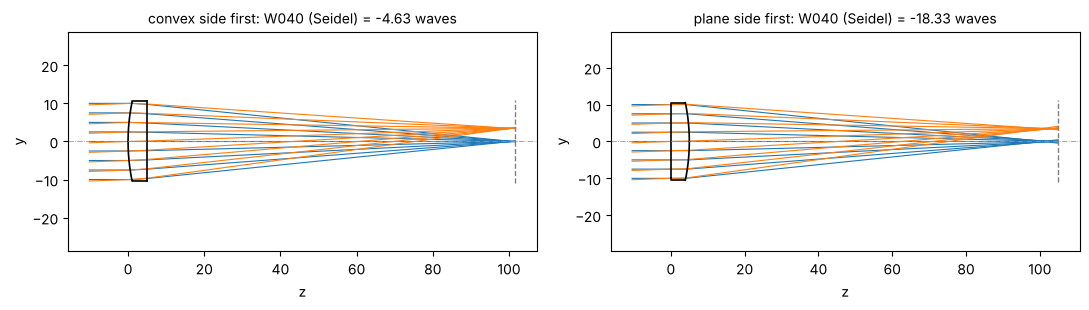

In [2]:
def plano_convex(convex_first=True, field=np.radians(2.0)):
    R = 100*(BK7[0] - 1)
    if convex_first:
        s = [rt.Surface(R, 5.0, material=BK7, semi_diameter=10.5), rt.Surface(np.inf, 95.0, n_after=1.0, semi_diameter=10.5)]
    else:
        s = [rt.Surface(np.inf, 5.0, material=BK7, semi_diameter=10.5), rt.Surface(-R, 95.0, n_after=1.0, semi_diameter=10.5)]
    return rt.System(s, 0, WL, field_angle=field, entrance_pupil_radius=10.0).at_paraxial_focus()

good, bad = plano_convex(True), plano_convex(False)
print(good)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, sys_, name in zip(axes, (good, bad), ("convex side first", "plane side first")):
    sys_.draw(ax, n_rays=9)
    ax.set_title("{}: W040 (Seidel) = {:.2f} waves".format(name, sys_.seidel(0.0).W040), fontsize=10)
plt.tight_layout()

The OPD maps and ray fans show the difference. The OPD is negative at the rim (W040 < 0), so the marginal
rays focus in front of the paraxial image and land on the opposite side of the axis. The fans have the
cubic shape of third-order spherical aberration.

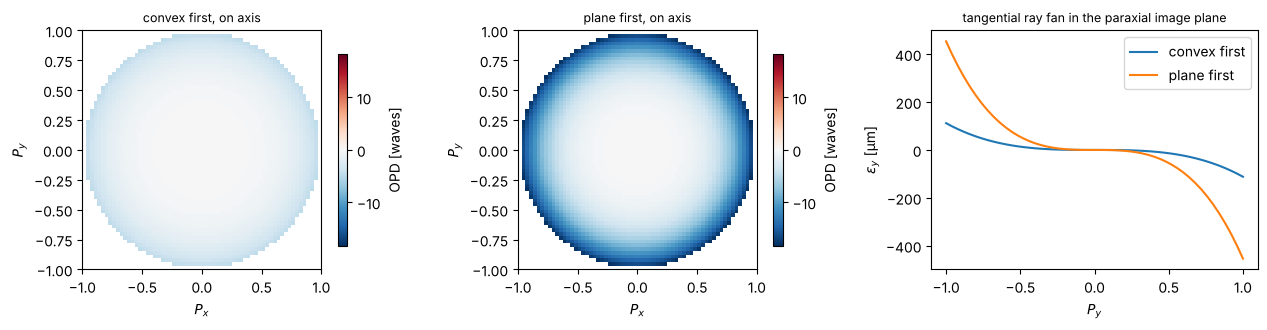

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
m_good, m_bad = good.opd(0.0, 64), bad.opd(0.0, 64)
vmax = np.nanmax(np.abs(m_bad.W))
show_opd(axes[0], m_good, "convex first, on axis", vmax)
show_opd(axes[1], m_bad, "plane first, on axis", vmax)
for sys_, name in zip((good, bad), ("convex first", "plane first")):
    fan = sys_.ray_fan(0.0)
    axes[2].plot(fan.p, 1e3*fan.ey, label=name)
axes[2].set_xlabel("$P_y$")
axes[2].set_ylabel(r"$\epsilon_y$ [µm]")
axes[2].set_title("tangential ray fan in the paraxial image plane", fontsize=9)
axes[2].legend()
plt.tight_layout()

### Real rays versus third-order (Seidel) theory

The radial profile of the real OPD has the form W040 ρ⁴ plus higher orders. The Seidel sum predicts W040
from two paraxial rays alone. At f/5 the higher orders are small. The bending curve below repeats a classic
result. Spherical aberration of a thin lens depends on its shape factor B = (c₁ + c₂)/(c₁ − c₂), and for
n = 1.5 its minimum lies close to the plano-convex form with the convex side first (B ≈ +0.7).

minimum at B = 0.70


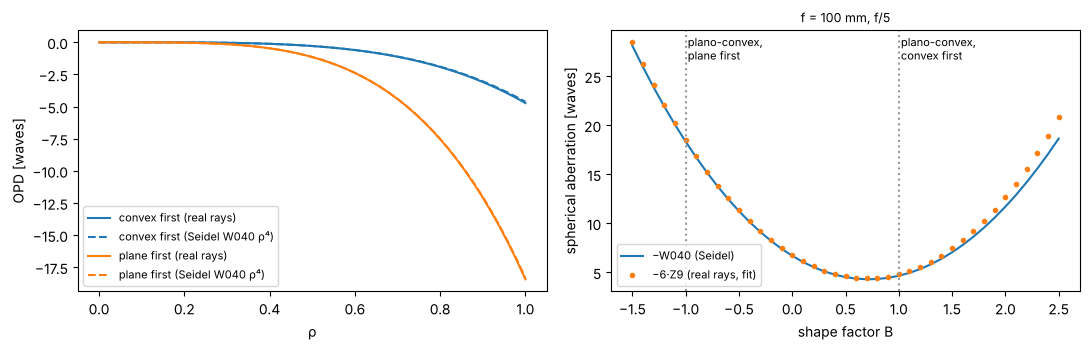

In [4]:
rho = np.linspace(0, 1, 51)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for sys_, name, c in zip((good, bad), ("convex first", "plane first"), ("C0", "C1")):
    b = sys_.trace_pupil(0.0, 0*rho, rho)
    W = sys_._opd(b, sys_.trace_pupil(0.0)) / WL
    axes[0].plot(rho, W, c, label=name + " (real rays)")
    axes[0].plot(rho, sys_.seidel(0.0).W040*rho**4, c + "--", label=name + " (Seidel W040 ρ⁴)")
axes[0].set_xlabel("ρ")
axes[0].set_ylabel("OPD [waves]")
axes[0].legend(fontsize=8)

# bending: keep f = 100 mm, vary the shape factor
P = 1/100/(BK7[0] - 1)                # c1 - c2
shapes = np.linspace(-1.5, 2.5, 41)
W040_s, rms_real = [], []
for B in shapes:
    c1, c2 = P*(B + 1)/2, P*(B - 1)/2
    s = [rt.Surface(1/c1 if c1 else np.inf, 3.0, material=BK7, semi_diameter=12),
         rt.Surface(1/c2 if c2 else np.inf, 95.0, n_after=1.0, semi_diameter=12)]
    sys_ = rt.System(s, 0, WL, entrance_pupil_radius=10.0).at_paraxial_focus()
    W040_s.append(sys_.seidel(0.0).W040)
    rms_real.append(sys_.zernike(0.0, 9, N=33)[8])   # Z9 = 6ρ⁴ - 6ρ² + 1
axes[1].plot(shapes, -np.array(W040_s), label="−W040 (Seidel)")
axes[1].plot(shapes, -6*np.array(rms_real), "o", ms=3, label="−6·Z9 (real rays, fit)")
axes[1].axvline(1, color="0.6", ls=":")
axes[1].axvline(-1, color="0.6", ls=":")
axes[1].text(1.02, axes[1].get_ylim()[1]*0.9, "plano-convex,\nconvex first", fontsize=8)
axes[1].text(-0.98, axes[1].get_ylim()[1]*0.9, "plano-convex,\nplane first", fontsize=8)
axes[1].set_xlabel("shape factor B")
axes[1].set_ylabel("spherical aberration [waves]")
axes[1].set_title("f = 100 mm, f/5", fontsize=9)
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
print("minimum at B = {:.2f}".format(shapes[np.argmin(np.abs(W040_s))]))

### Paraxial cross-check with `abcd`

The y-nu trace and the matrices of `pyoptics.abcd` give the same system matrix and the same cardinal points.
`System.to_abcd()` converts the system into an `abcd.OpticalSystem`, for example to trace Gaussian beams.

In [5]:
p = good.paraxial()
R = 100*(BK7[0] - 1)
M = abcd.thick_lens(R, np.inf, 5.0, good.n[1])
cp = abcd.cardinal_points(M, 5.0)
print("matrix (raytrace):\n", p.matrix, "\nmatrix (abcd.thick_lens):\n", M)
print("EFL {:.4f} / {:.4f} mm, BFL {:.4f} / {:.4f} mm".format(p.efl, cp.f_prime, p.bfl, cp.bfl))
print("entrance pupil at z = {:.2f}, radius {:.2f}; exit pupil at z = {:.3f}, radius {:.3f}".format(
    p.ep_z, p.ep_radius, p.xp_z, p.xp_radius))
print("F/# = {:.3f}, image space NA = {:.4f}".format(p.f_number, p.na))

matrix (raytrace):
 [[ 0.96703586  3.2964135 ]
 [-0.01        1.        ]] 
matrix (abcd.thick_lens):
 [[ 0.96703586  3.2964135 ]
 [-0.01        1.        ]]
EFL 100.0000 / 100.0000 mm, BFL 96.7036 / 96.7036 mm
entrance pupil at z = 0.00, radius 10.00; exit pupil at z = 1.704, radius 10.000
F/# = 5.000, image space NA = 0.1000


## 2 The parabolic mirror: perfect on axis, coma off axis

A paraboloid (K = −1) images an on-axis point at infinity without aberrations. The conic term exactly
cancels the spherical aberration of the vertex sphere, both in the Seidel sum and in the real trace. Off axis,
the mirror shows coma that grows linearly with the field. Relative to the chief ray, coma is W131 ρ³ cos θ, so
the maps look like a tilt that grows with the cube of the pupil radius. After the mirror, light travels in −z, so the
image distance is negative.

parabola: max |OPD| on axis = 2.4e-10 waves, Seidel S_I = -1.7e-18
sphere:   W040 = -2.60 waves (Seidel), Strehl 0.056


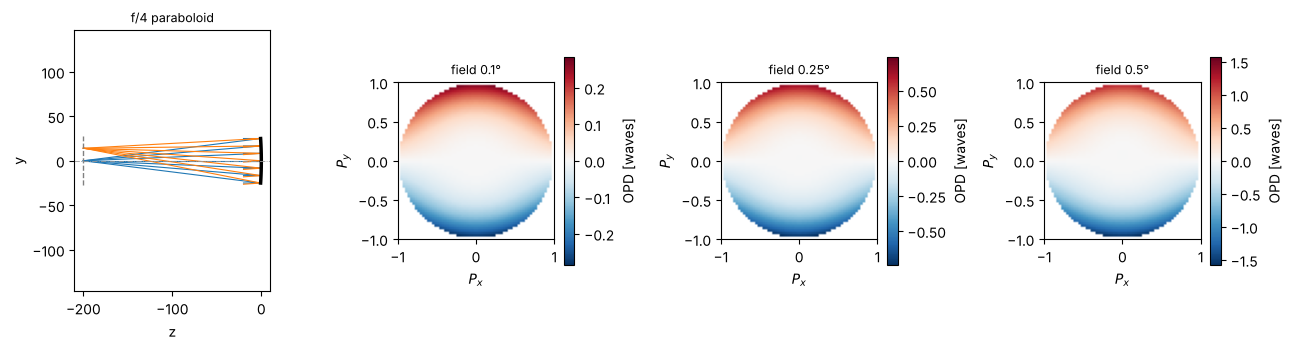

In [6]:
f_mirror = 200.0
parabola = rt.System([rt.Surface(-2*f_mirror, -f_mirror, conic=-1.0, mirror=True, semi_diameter=25.0)], 0, WL,
                     field_angle=np.radians(0.5))
sphere = rt.System([rt.Surface(-2*f_mirror, -f_mirror, mirror=True, semi_diameter=25.0)], 0, WL).at_paraxial_focus()
print("parabola: max |OPD| on axis = {:.1e} waves, Seidel S_I = {:.1e}".format(
    np.nanmax(np.abs(parabola.opd(0.0).W)), parabola.seidel().total[0]))
print("sphere:   W040 = {:.2f} waves (Seidel), Strehl {:.3f}".format(sphere.seidel(0.0).W040, sphere.strehl(0.0)))

fig = plt.figure(figsize=(13, 3.6))
ax = fig.add_subplot(1, 4, 1)
parabola.draw(ax, fields=[0.0, np.radians(4.0)], n_rays=7)
ax.set_title("f/4 paraboloid", fontsize=9)
for j, deg in enumerate([0.1, 0.25, 0.5]):
    ax = fig.add_subplot(1, 4, j + 2)
    show_opd(ax, parabola.opd(np.radians(deg), 64), "field {}°".format(deg))
plt.tight_layout()

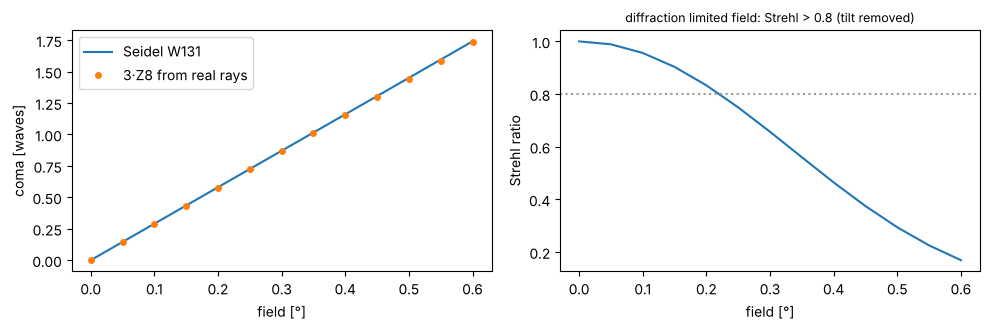

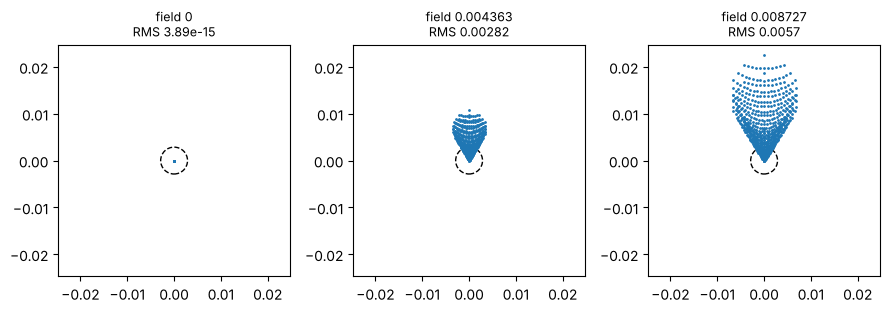

In [7]:
fields = np.radians(np.linspace(0, 0.6, 13))
W131 = [parabola.seidel(f).W131 for f in fields]
c8 = [parabola.zernike(f, 9, N=33)[7] for f in fields]   # Z8 = (3ρ³ - 2ρ) sin φ: coma along y
strehl = [parabola.strehl(f) for f in fields]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(np.degrees(fields), W131, label="Seidel W131")
axes[0].plot(np.degrees(fields), 3*np.array(c8), "o", ms=4, label="3·Z8 from real rays")
axes[0].set_xlabel("field [°]")
axes[0].set_ylabel("coma [waves]")
axes[0].legend()
axes[1].plot(np.degrees(fields), strehl)
axes[1].axhline(0.8, color="0.6", ls=":")
axes[1].set_xlabel("field [°]")
axes[1].set_ylabel("Strehl ratio")
axes[1].set_title("diffraction limited field: Strehl > 0.8 (tilt removed)", fontsize=9)
plt.tight_layout()

axes = parabola.plot_spot_diagram([0.0, np.radians(0.25), np.radians(0.5)])
for ax in axes:
    ax.add_patch(plt.Circle((0, 0), 0.61*WL/0.125, fill=False, color="k", ls="--"))
plt.tight_layout()

## 3 An achromatic doublet

A cemented BK7/F2 doublet with f = 100 mm at f/5. The powers of the two lenses follow from the thin lens
achromat condition φ₁/V₁ + φ₂/V₂ = 0. This leaves one degree of freedom, the bending (R₁). The Seidel sums
show that this glass pair can correct either spherical aberration or coma, but not both. We choose the
bending with W040 = 0 near R₁ ≈ 50 mm. For thick lenses, the thin lens powers leave a small residual of
primary colour, so the last radius is adjusted until the F and C foci coincide.

The refractive indices come from `materials.abbe_dispersion` (material=(n_d, V_d)), so the same system can be
traced at any wavelength with `System.with_wavelength()`.

System(wavelength=0.0005875618, stop_index=0, object_distance=inf, max_field=0.05235987755982989)
   0* Surface(R=47.38088426644606, thickness=5.0, n_after=None, material=(1.5168, 64.17), conic=0.0, aspheric=(), semi_diameter=10.0) n'=1.516800
   1  Surface(R=-42.44630873834396, thickness=2.0, n_after=None, material=(1.62, 36.37), conic=0.0, aspheric=(), semi_diameter=11.0) n'=1.620000
   2  Surface(R=-517.4491581775943, thickness=98.23639517089624, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=11.0) n'=1.000000


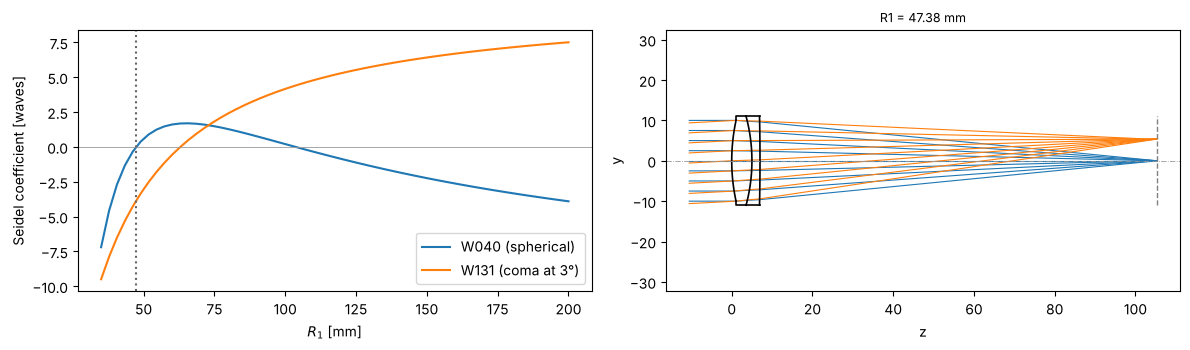

In [8]:
f = 100.0
phi1 = BK7[1]/(BK7[1] - F2[1])/f
phi2 = -F2[1]/(BK7[1] - F2[1])/f

from scipy.optimize import brentq

def doublet(c1, field=np.radians(3.0)):
    c2 = c1 - phi1/(BK7[0] - 1)
    def build(c3):
        s = [rt.Surface(1/c1, 5.0, material=BK7, semi_diameter=11.0, label="BK7"),
             rt.Surface(1/c2, 2.0, material=F2, semi_diameter=11.0, label="F2"),
             rt.Surface(1/c3, 95.0, n_after=1.0, semi_diameter=11.0)]
        return rt.System(s, 0, WL, field_angle=field, entrance_pupil_radius=10.0)
    c3_thin = c2 - phi2/(F2[0] - 1)
    colour = lambda c3: (build(c3).with_wavelength(486.1327e-6).paraxial().image_distance
                         - build(c3).with_wavelength(656.2725e-6).paraxial().image_distance)
    c3 = brentq(colour, c3_thin - 2e-3, c3_thin + 2e-3)
    return build(c3).at_paraxial_focus()

R1 = np.linspace(35, 200, 60)
sums = np.array([[doublet(1/r).seidel().W040, doublet(1/r).seidel().W131] for r in R1])

R1_best = brentq(lambda r: doublet(1/r).seidel().W040, 45, 55)
dbl = doublet(1/R1_best)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(R1, sums[:, 0], label="W040 (spherical)")
axes[0].plot(R1, sums[:, 1], label="W131 (coma at 3°)")
axes[0].axhline(0, color="0.6", lw=0.6)
axes[0].axvline(R1_best, color="0.4", ls=":")
axes[0].set_xlabel("$R_1$ [mm]")
axes[0].set_ylabel("Seidel coefficient [waves]")
axes[0].legend()
dbl.draw(axes[1], fields=[0, np.radians(3.0)], n_rays=9)
axes[1].set_title("R1 = {:.2f} mm".format(R1_best), fontsize=9)
plt.tight_layout()
print(dbl)

### Chromatic focal shift

The paraxial focus position over the visible range for the doublet and for a BK7 singlet of the same focal
length. The singlet shows the longitudinal colour f/V ≈ 1.6 mm between F and C. The doublet brings F and C
to the same focus. Real glass pairs then leave the secondary spectrum, an offset of the d focus of about f/2000.
The two-term Cauchy model of `abbe_dispersion` gives every glass the same relative partial dispersion, so it
predicts almost no secondary spectrum (the sub-micron residual below). For the secondary spectrum, pass a
Sellmeier formula as `material=lambda wavelength_nm: ...`.

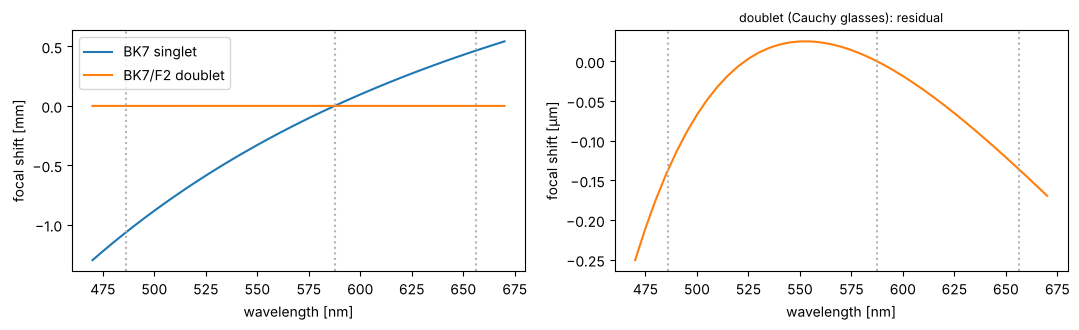

In [9]:
wls = np.linspace(470, 670, 41)*1e-6
singlet = plano_convex(True)
shift = lambda sys_: np.array([sys_.with_wavelength(w).paraxial().image_distance for w in wls])
d_dbl = shift(dbl) - dbl.paraxial().image_distance
d_sgl = shift(singlet) - singlet.paraxial().image_distance

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(wls*1e6, d_sgl, label="BK7 singlet")
axes[0].plot(wls*1e6, d_dbl, label="BK7/F2 doublet")
axes[1].plot(wls*1e6, 1e3*d_dbl, "C1")
for ax in axes:
    for l in (486.13, 587.56, 656.27):
        ax.axvline(l, color="0.7", ls=":")
    ax.set_xlabel("wavelength [nm]")
axes[0].set_ylabel("focal shift [mm]")
axes[1].set_ylabel("focal shift [µm]")
axes[1].set_title("doublet (Cauchy glasses): residual", fontsize=9)
axes[0].legend()
plt.tight_layout()

### Field aberrations: OPD maps, Zernikes and field curves

Over the field, coma and astigmatism appear, together with the Petzval curvature of the image. The
tangential and sagittal foci follow from the ρ² terms of the OPD. A defocus W₂ρ² corresponds to a focus
shift Δz = +2W₂/(n′ NA²) of the focus (behind the image plane for W₂ > 0). Because the reference sphere sits at the paraxial image plane, the Seidel values
W220 and W220 + W222 give the third-order field curves directly.

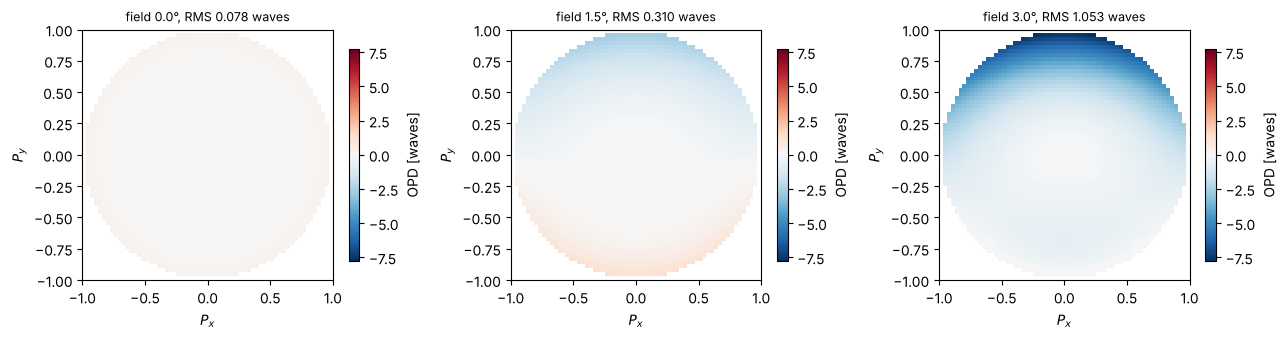

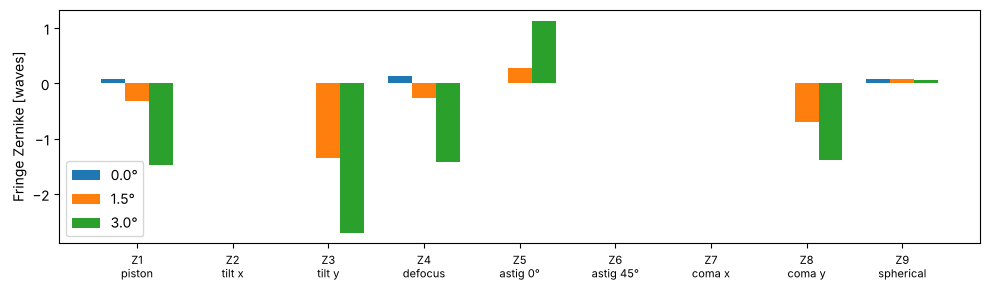

In [10]:
fields_deg = [0.0, 1.5, 3.0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
maps = [dbl.opd(np.radians(d), 64) for d in fields_deg]
vmax = max(np.nanmax(np.abs(m.W)) for m in maps)
for ax, d, m in zip(axes, fields_deg, maps):
    show_opd(ax, m, "field {}°, RMS {:.3f} waves".format(d, dbl.rms_opd(np.radians(d))), vmax)
plt.tight_layout()

names = ["piston", "tilt x", "tilt y", "defocus", "astig 0°", "astig 45°", "coma x", "coma y", "spherical"]
fig, ax = plt.subplots(figsize=(10, 3))
for j, d in enumerate(fields_deg):
    ax.bar(np.arange(1, 10) + 0.25*(j - 1), dbl.zernike(np.radians(d), 9), width=0.25, label="{}°".format(d))
ax.set_xticks(np.arange(1, 10))
ax.set_xticklabels(["Z{}\n{}".format(j, n) for j, n in zip(range(1, 10), names)], fontsize=8)
ax.set_ylabel("Fringe Zernike [waves]")
ax.legend()
plt.tight_layout()

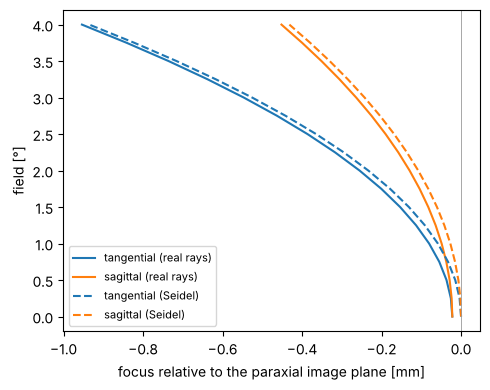

In [11]:
fields = np.radians(np.linspace(0, 4, 17))
na = dbl.paraxial().na
z_t, z_s, z_t3, z_s3 = [], [], [], []
for fld in fields:
    m = dbl.opd(fld, 33)
    PX, PY = np.meshgrid(m.px, m.py)
    ok = np.isfinite(m.W)
    x, y = PX[ok], PY[ok]
    r2 = x**2 + y**2
    c = np.linalg.lstsq(np.column_stack([np.ones_like(x), r2, r2**2, r2*y, y**2, y]), m.W[ok], rcond=None)[0]
    to_dz = lambda W2: 2*W2*WL/na**2
    z_s.append(to_dz(c[1]))
    z_t.append(to_dz(c[1] + c[4]))
    s = dbl.seidel(fld)
    z_s3.append(to_dz(s.W220))
    z_t3.append(to_dz(s.W220 + s.W222))

fig, ax = plt.subplots(figsize=(5, 4))
deg = np.degrees(fields)
ax.plot(z_t, deg, "C0", label="tangential (real rays)")
ax.plot(z_s, deg, "C1", label="sagittal (real rays)")
ax.plot(z_t3, deg, "C0--", label="tangential (Seidel)")
ax.plot(z_s3, deg, "C1--", label="sagittal (Seidel)")
ax.axvline(0, color="0.6", lw=0.6)
ax.set_xlabel("focus relative to the paraxial image plane [mm]")
ax.set_ylabel("field [°]")
ax.legend(fontsize=8)
plt.tight_layout()

## 4 Hand-off to wave optics: PSF, MTF and Strehl

`System.pupil()` gives the image space NA and the traced pupil phase as callables in the coordinates of
`pyoptics.imaging`. These coordinates are the transverse wave vector (P_x, P_y) = n′(d_x, d_y)/NA of the image
space rays relative to the chief ray, so a ray from the top of the pupil, which travels downwards, lands at
P_y < 0. `System.psf()` and `System.mtf()` pass them on to `imaging.get_psf()` and `imaging.get_mtf()`. The PSF
grid is centred on the chief ray image point.

First a check: the paraboloid on axis gives the Airy pattern of its NA.

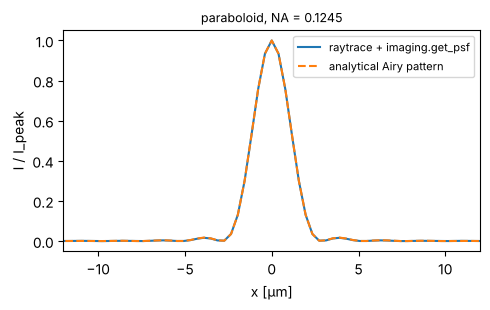

In [12]:
x = grid1d(-0.05, 0.05, 256)
pup = parabola.pupil(0.0)
psf = parabola.psf(x, x, 0.0)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(x*1e3, np.abs(psf[128])**2, label="raytrace + imaging.get_psf")
ax.plot(x*1e3, airy_pattern(x, pup.NA, WL), "--", label="analytical Airy pattern")
ax.set_xlim(-12, 12)
ax.set_xlabel("x [µm]")
ax.set_ylabel("I / I_peak")
ax.set_title("paraboloid, NA = {:.4f}".format(pup.NA), fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()

PSFs of the doublet stopped down to f/8 across the field, and the spot diagrams on the same scale (the circle
is the Airy disk). With aberrations of about a wave, the geometrical spot and the diffraction pattern both show
the comatic and astigmatic shapes. The PSF centroid and the ray centroid agree, which checks the orientation of the pupil
hand-off.

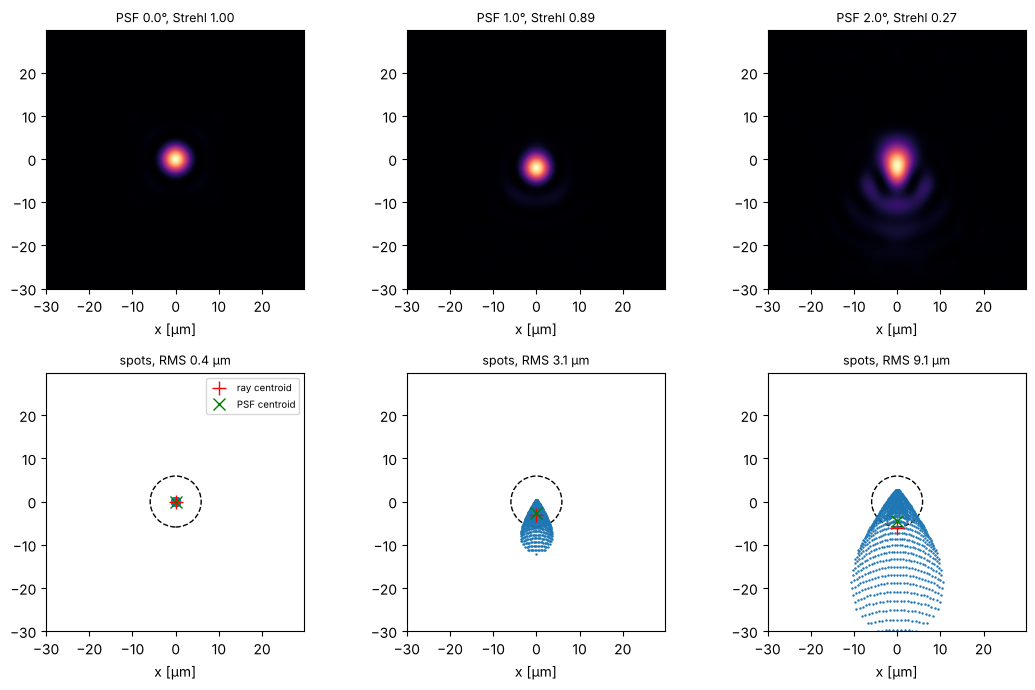

In [13]:
dbl8 = rt.System(dbl.surfaces, 0, WL, field_angle=np.radians(2.0), entrance_pupil_radius=6.25)
fields_deg = [0.0, 1.0, 2.0]
x = grid1d(-0.03, 0.03, 256)
X, Y = np.meshgrid(x, x)
airy_r = 0.61*WL/dbl8.pupil(0.0).NA
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for j, d in enumerate(fields_deg):
    fld = np.radians(d)
    I = np.abs(dbl8.psf(x, x, fld))**2
    axes[0, j].imshow(I, extent=1e3*np.array([x[0], x[-1], x[0], x[-1]]), origin="lower", cmap="magma")
    axes[0, j].set_title("PSF {}°, Strehl {:.2f}".format(d, dbl8.strehl(fld)), fontsize=9)
    spot = dbl8.spot_diagram(fld, 41)
    axes[1, j].plot(1e3*spot.x, 1e3*spot.y, ".", ms=1.5)
    axes[1, j].add_patch(plt.Circle((0, 0), 1e3*airy_r, fill=False, color="k", ls="--"))
    axes[1, j].plot(1e3*spot.centroid[0], 1e3*spot.centroid[1], "r+", ms=10, label="ray centroid")
    cy, cx = np.sum(Y*I)/np.sum(I), np.sum(X*I)/np.sum(I)
    axes[1, j].plot(1e3*cx, 1e3*cy, "gx", ms=8, label="PSF centroid")
    axes[1, j].set_xlim(1e3*x[0], 1e3*x[-1])
    axes[1, j].set_ylim(1e3*x[0], 1e3*x[-1])
    axes[1, j].set_aspect("equal")
    axes[1, j].set_title("spots, RMS {:.1f} µm".format(1e3*spot.rms), fontsize=9)
    for ax in axes[:, j]:
        ax.set_xlabel("x [µm]")
axes[1, 0].legend(fontsize=7)
plt.tight_layout()

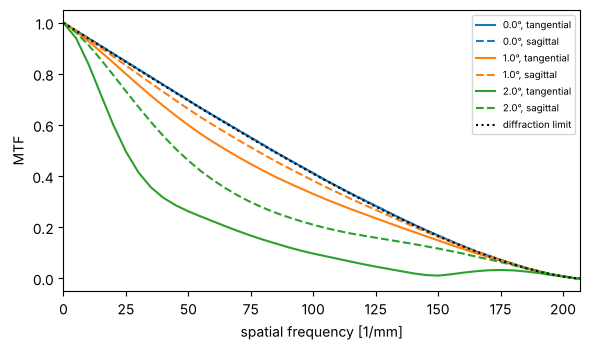

In [14]:
x = grid1d(-0.1, 0.1, 256)
fx = np.fft.fftshift(np.fft.fftfreq(len(x), x[1] - x[0]))
c = len(x)//2
NA0 = dbl8.pupil(0.0).NA
fig, ax = plt.subplots(figsize=(6, 3.6))
for j, d in enumerate(fields_deg):
    mtf = dbl8.mtf(x, x, np.radians(d))
    ax.plot(fx[c:], mtf[c:, c], "C{}".format(j), label="{}°, tangential".format(d))
    ax.plot(fx[c:], mtf[c, c:], "C{}--".format(j), label="{}°, sagittal".format(d))
nu = fx[c:]/(2*NA0/WL)
ax.plot(fx[c:], np.where(nu < 1, 2/np.pi*(np.arccos(np.clip(nu, 0, 1)) - nu*np.sqrt(1 - np.clip(nu, 0, 1)**2)), 0),
        "k:", label="diffraction limit")
ax.set_xlim(0, 2*NA0/WL)
ax.set_xlabel("spatial frequency [1/mm]")
ax.set_ylabel("MTF")
ax.legend(fontsize=7)
plt.tight_layout()

### Through focus

Moving the image plane (`with_image_distance()`) adds the defocus term to the OPD. Spherical aberration and its
balancing defocus make the Strehl curve asymmetric. For the plano-convex lens at f/10, the best focus lies in
front of the paraxial focus, half way to the marginal focus (the classic best focus for third-order
spherical aberration, which balances W040 ρ⁴ with −W040 ρ²).

best focus at -0.140 mm, LSA = 0.274 mm


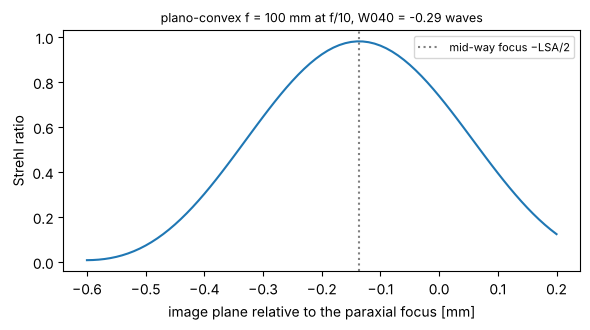

In [15]:
lens = rt.System(plano_convex(True).surfaces, 0, WL, entrance_pupil_radius=5.0).at_paraxial_focus()
d0 = lens.paraxial().image_distance
dz = np.linspace(-0.6, 0.2, 81)
S = [lens.with_image_distance(d0 + z).strehl(0.0, N=41) for z in dz]
lsa = -lens.ray_fan(0.0).ey[-1]/abs(lens.paraxial().marginal[-1, 1])   # longitudinal aberration of the marginal ray
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(dz, S)
ax.axvline(-lsa/2, color="0.5", ls=":", label="mid-way focus −LSA/2")
ax.set_xlabel("image plane relative to the paraxial focus [mm]")
ax.set_ylabel("Strehl ratio")
ax.set_title("plano-convex f = 100 mm at f/10, W040 = {:.2f} waves".format(lens.seidel(0.0).W040), fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()
print("best focus at {:.3f} mm, LSA = {:.3f} mm".format(dz[np.argmax(S)], lsa))

## 5 Tilts, decentres and fold mirrors

Each surface takes `decenter=(dx, dy)` and `tilt=(a_x, a_y, a_z)` (radians, rotations about the local x, y
and z axes, applied after the decentre). Like Zemax's "decenter and return", these move only that surface. The
axis of the following surfaces stays where it is, and the thickness is measured along the untilted axis. A
`CoordinateBreak` moves the axis for all following surfaces, which is what fold mirrors and tilted
sub-assemblies need. The image plane can be tilted with `image_tilt` of `System`. Paraxial data
(`paraxial()`, `seidel()`, the pupils) belong to the nominal system with all tilts set to zero, while real
rays always see the actual geometry. Spots, fans, OPDs and PSFs are evaluated in the local frame of the image
plane.

### Fold mirror

A 45° mirror behind the doublet folds the beam from +z to +y (a positive a_x turns +z towards −y, and the
reflection sends the light to +y). Behind the mirror, light travels in −z of the new frame, so the last
thickness is negative. The image is unchanged.

max |OPD(folded) - OPD(straight)| = 4.8e-11 waves


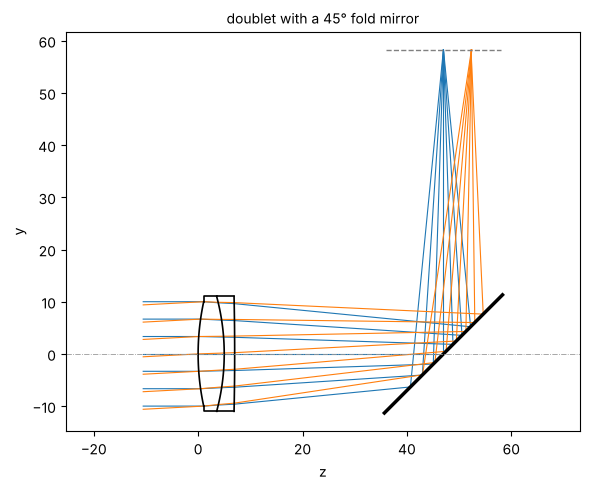

In [16]:
d_img = dbl.surfaces[-1].thickness
folded = dbl.copy().surfaces
folded[-1].thickness = 40.0
folded += [rt.CoordinateBreak(tilt=(np.pi/4, 0, 0)), rt.Surface(np.inf, 0.0, mirror=True, semi_diameter=16.0),
           rt.CoordinateBreak(tilt=(np.pi/4, 0, 0), thickness=-(d_img - 40.0))]
fold = rt.System(folded, 0, WL, field_angle=np.radians(3.0))

fig, ax = plt.subplots(figsize=(6, 5))
fold.draw(ax, fields=[0.0, np.radians(3.0)], n_rays=7)
ax.set_title("doublet with a 45° fold mirror", fontsize=10)
plt.tight_layout()
print("max |OPD(folded) - OPD(straight)| = {:.1e} waves".format(
    np.nanmax(np.abs(fold.opd(np.radians(3.0), 33).W - dbl.opd(np.radians(3.0), 33).W))))

### A decentred element: coma on axis

Decentring the F2 element of the cemented doublet (both of its surfaces) breaks the rotational symmetry. Even
on axis, the image shows coma that grows linearly with the decentre, plus a lateral image shift (tilt). This is
the basic sensitivity that alignment tolerances are derived from.

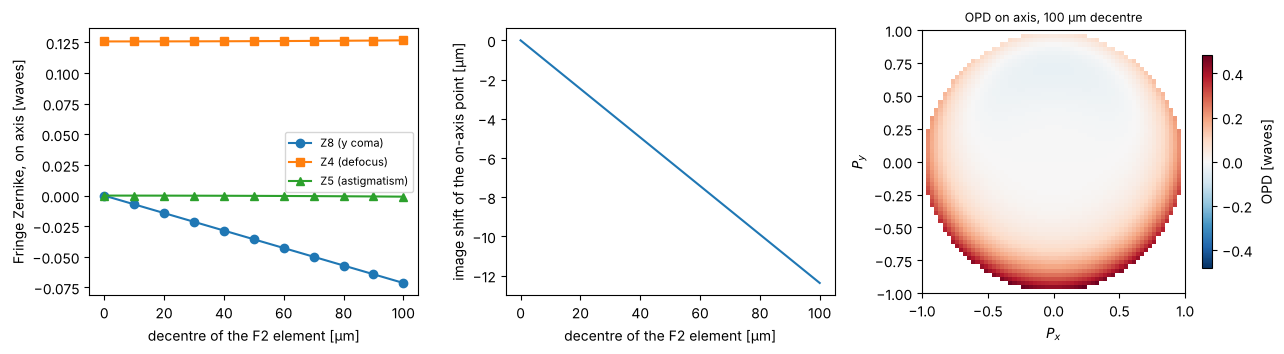

In [17]:
def decentred(dy):
    s = dbl.copy().surfaces
    for i in (1, 2):
        s[i].decenter = (0.0, dy)
    return rt.System(s, 0, WL, entrance_pupil_radius=10.0)

dys = np.linspace(0, 0.1, 11)
coeffs = np.array([decentred(dy).zernike(0.0, 9, N=33) for dy in dys])
shift = [decentred(dy).trace_pupil(0.0).points[-1, 0, 1] for dy in dys]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(1e3*dys, coeffs[:, 7], "o-", label="Z8 (y coma)")
axes[0].plot(1e3*dys, coeffs[:, 3], "s-", label="Z4 (defocus)")
axes[0].plot(1e3*dys, coeffs[:, 4], "^-", label="Z5 (astigmatism)")
axes[0].set_xlabel("decentre of the F2 element [µm]")
axes[0].set_ylabel("Fringe Zernike, on axis [waves]")
axes[0].legend(fontsize=8)
axes[1].plot(1e3*dys, 1e3*np.array(shift))
axes[1].set_xlabel("decentre of the F2 element [µm]")
axes[1].set_ylabel("image shift of the on-axis point [µm]")
show_opd(axes[2], decentred(0.1).opd(0.0, 64), "OPD on axis, 100 µm decentre")
plt.tight_layout()

### A tilted plate in a converging beam: astigmatism

A plane-parallel plate tilted by θ in a converging beam separates the tangential and sagittal foci. Smith
(*Modern Optical Engineering*) gives the exact longitudinal astigmatism of a thin pencil,
$$L_{as} = \frac{t}{\sqrt{n^2-\sin^2\theta}}\left(\frac{n^2\cos^2\theta}{n^2-\sin^2\theta}-1\right).$$
Below, the two foci are found from narrow real-ray fans around the chief ray and compared with this formula.
The OPD maps show the astigmatism together with the coma of the plate.

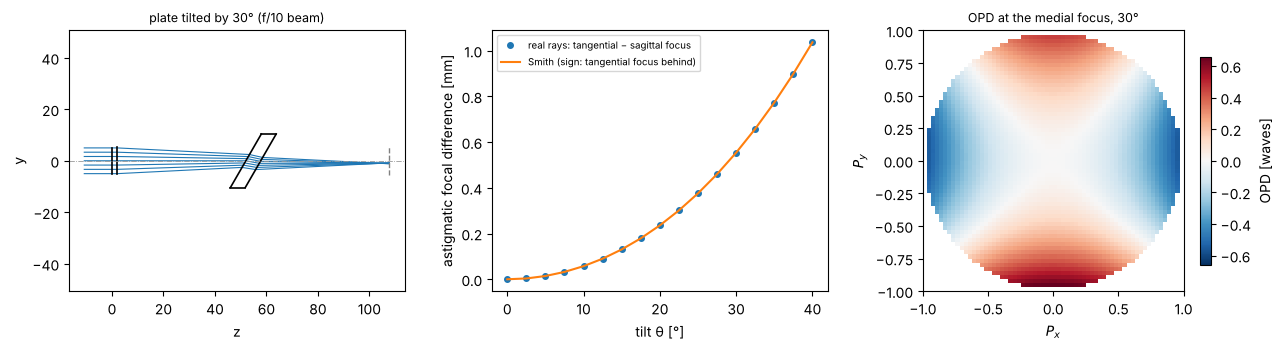

In [18]:
n_p, t_p = BK7[0], 5.0

def plate(theta):
    s = [rt.Surface(np.inf, 2.0, semi_diameter=5.0), rt.IdealLens(100.0, 50.0),
         rt.Surface(np.inf, t_p/np.cos(theta), material=BK7, tilt=(theta, 0, 0), semi_diameter=12),
         rt.Surface(np.inf, 50.0, n_after=1.0, tilt=(theta, 0, 0), semi_diameter=12)]
    return rt.System(s, 0, WL)

def foci(system, e=0.01):
    b = system.trace_pupil(0.0, [0, 0, 0, e, -e], [0, e, -e, 0, 0])
    P, d = system.to_image_frame(b.points[-1], b.directions[-1])
    def crossing(i, j):
        s = np.linalg.lstsq(np.array([d[i], -d[j]]).T, P[j] - P[i], rcond=None)[0]
        return np.dot(P[i] + s[0]*d[i] - P[0], d[0])
    return crossing(1, 2), crossing(3, 4)

thetas = np.radians(np.linspace(0, 40, 17))
L_ray = np.array([np.subtract(*foci(plate(th))) for th in thetas])
L_smith = t_p/np.sqrt(n_p**2 - np.sin(thetas)**2)*(n_p**2*np.cos(thetas)**2/(n_p**2 - np.sin(thetas)**2) - 1)

fig = plt.figure(figsize=(13, 3.6))
ax = fig.add_subplot(1, 3, 1)
plate(np.radians(30)).draw(ax, n_rays=7)
ax.set_title("plate tilted by 30° (f/10 beam)", fontsize=9)
ax = fig.add_subplot(1, 3, 2)
ax.plot(np.degrees(thetas), L_ray, "o", ms=4, label="real rays: tangential − sagittal focus")
ax.plot(np.degrees(thetas), -L_smith, label="Smith (sign: tangential focus behind)")
ax.set_xlabel("tilt θ [°]")
ax.set_ylabel("astigmatic focal difference [mm]")
ax.legend(fontsize=7)
ax = fig.add_subplot(1, 3, 3)
system = plate(np.radians(30))
mid = np.mean(foci(system))
show_opd(ax, system.with_image_distance(50.0 + mid).opd(0.0, 64), "OPD at the medial focus, 30°")
plt.tight_layout()

## 6 A lithography projection lens

J. Brian Caldwell's all-fused-silica KrF projection lens (*Optics & Photonics News* **9**(11), 40–41, 1998)
is one of the few published microlithography designs with a complete prescription. It has 21 elements of a
single glass, reduces 4×, has an image side NA of 0.56, a 23.4 mm image field, and measures 1 m from reticle to
wafer. The design is telecentric on both sides. Its three bulges (positive groups) and two waists (negative
groups) flatten the field: the waists carry the strong negative power that cancels the Petzval sum of the
positive groups. `raytrace.caldwell_krf_lens()` builds it with fused silica after Malitson's Sellmeier formula
(n = 1.5084 at 248.3 nm). The table does not mark the stop. Surface 30 limits the axial beam to exactly NA 0.56
and makes the chief rays telecentric to a few mrad, so it serves as the stop.

The lens is a dry KrF design of 1998. Today's ArF immersion scanners reach NA 1.35 with catadioptric lenses
in water; that is out of reach for this design, whose NA and ray angles are those of a dry NA 0.56 lens. The
lithography notebooks use it as a real, traceable *model* of a projection lens (aberrations, slit, Jones
pupil), and use a generic ArF immersion projector wherever they work at NA 1.35.

NA = 0.5603, magnification = -0.25000, reticle to wafer = 1000.01 mm


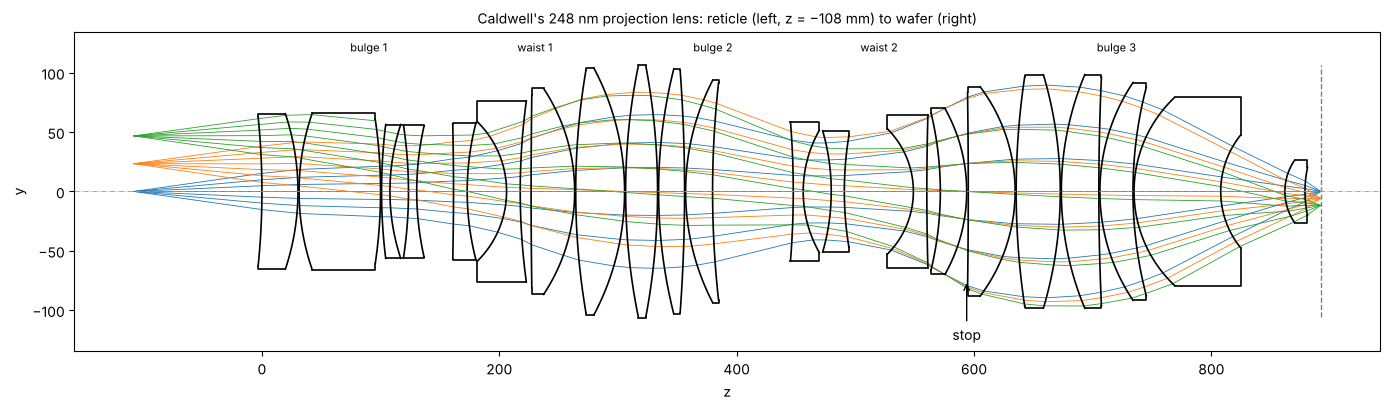

In [19]:
litho = rt.caldwell_krf_lens()
WL_KrF = litho.wavelength
fields_obj = [0.0, 23.4, 33.1, 46.8]          # object heights (reticle), image heights are 4x smaller
print("NA = {:.4f}, magnification = {:.5f}, reticle to wafer = {:.2f} mm".format(
    litho.pupil(0.0, 33).NA, litho.paraxial().magnification, 107.954 + sum(s.thickness for s in litho.surfaces)))

fig, ax = plt.subplots(figsize=(14, 4.2))
litho.draw(ax, fields=[0.0, 23.4, 46.8], n_rays=7, lw=0.6)
z_stop = litho.vertex_z[litho.stop_index]
ax.annotate("stop", (z_stop, -75), (z_stop, -125), ha="center", arrowprops=dict(arrowstyle="->"))
for z, name in ((90, "bulge 1"), (230, "waist 1"), (380, "bulge 2"), (520, "waist 2"), (720, "bulge 3")):
    ax.text(z, 118, name, ha="center", fontsize=8)
ax.set_title("Caldwell's 248 nm projection lens: reticle (left, z = −108 mm) to wafer (right)", fontsize=10)
plt.tight_layout()

### Wavefront over the field

The design is close to the diffraction limit over the whole field. The RMS OPD lies between 0.03 and 0.09
waves, around the Maréchal limit of 0.07 waves (Strehl ≈ 0.8), with the image plane at the paraxial focus and
no further refocusing. The residual is high order spherical aberration on axis, with astigmatism, coma and
trefoil towards the edge of the field.

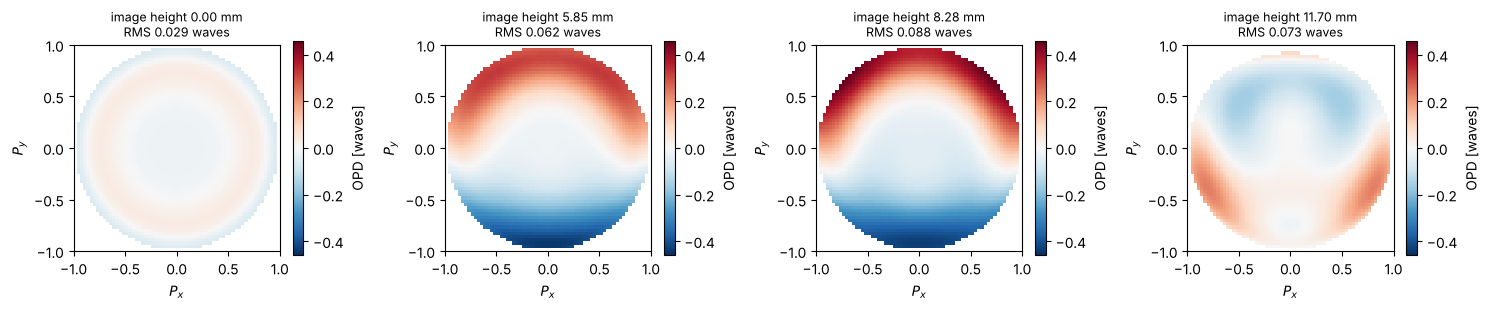

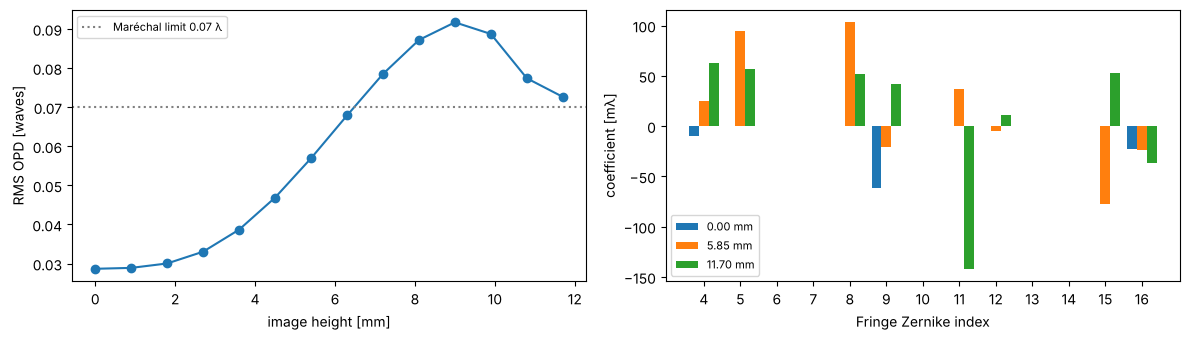

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
maps = [litho.opd(h, 64) for h in fields_obj]
vmax = max(np.nanmax(np.abs(m.W - np.nanmean(m.W))) for m in maps)
for ax, h, m in zip(axes, fields_obj, maps):
    show_opd(ax, rt.OPDMap(m.px, m.py, m.W - np.nanmean(m.W)),
             "image height {:.2f} mm\nRMS {:.3f} waves".format(h/4, litho.rms_opd(h, 64)), vmax)
plt.tight_layout()

hs = np.linspace(0, 46.8, 14)
rms = [litho.rms_opd(h, 33) for h in hs]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(hs/4, rms, "o-")
axes[0].axhline(0.07, color="0.5", ls=":", label="Maréchal limit 0.07 λ")
axes[0].set_xlabel("image height [mm]")
axes[0].set_ylabel("RMS OPD [waves]")
axes[0].legend(fontsize=8)
names = ["", "tilt x", "tilt y", "defocus", "astig 0°", "astig 45°", "coma x", "coma y", "spherical",
         "trefoil 0°", "trefoil 30°", "", "", "", "", "", "Z16 sph."]
for j, h in enumerate([0.0, 23.4, 46.8]):
    c = litho.zernike(h, 16, N=48)
    axes[1].bar(np.arange(4, 17) + 0.27*(j - 1), 1e3*c[3:16], width=0.27, label="{:.2f} mm".format(h/4))
axes[1].set_xticks(np.arange(4, 17))
axes[1].set_xlabel("Fringe Zernike index")
axes[1].set_ylabel("coefficient [mλ]")
axes[1].legend(fontsize=8)
plt.tight_layout()

### Telecentricity and distortion

Lithography lenses specify both, in milliradians and nanometres. A chief ray that is not parallel to the axis
on the wafer side turns defocus into an overlay error. The distortion is the deviation of the real chief ray
from −h/4. Its linear part is a magnification error, which the scanner corrects by adjusting the reticle
position, so the residual after removing the best fitting magnification is shown as well.

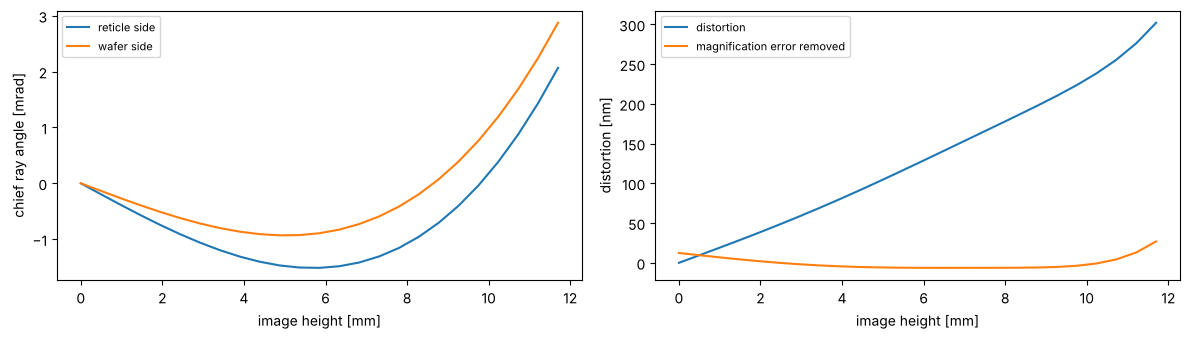

In [21]:
hs = np.linspace(0, 46.8, 25)
chief = [litho.trace_pupil(h) for h in hs]
tele_obj = [1e3*c.directions[0, 0, 1] for c in chief]
tele_img = [1e3*c.directions[-1, 0, 1] for c in chief]
dist = [1e6*(c.points[-1, 0, 1] + h/4) for c, h in zip(chief, hs)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(hs/4, tele_obj, label="reticle side")
axes[0].plot(hs/4, tele_img, label="wafer side")
axes[0].set_xlabel("image height [mm]")
axes[0].set_ylabel("chief ray angle [mrad]")
axes[0].legend(fontsize=8)
lin = np.polyfit(hs/4, dist, 1)
axes[1].plot(hs/4, dist, label="distortion")
axes[1].plot(hs/4, dist - np.polyval(lin, hs/4), label="magnification error removed")
axes[1].legend(fontsize=8)
axes[1].set_xlabel("image height [mm]")
axes[1].set_ylabel("distortion [nm]")
plt.tight_layout()

### PSF and MTF at NA 0.56

The pupil hand-off works as for the small lenses. At the edge of the field the PSF is still close to the Airy
pattern, whose first zero lies at 0.61 λ/NA = 270 nm.

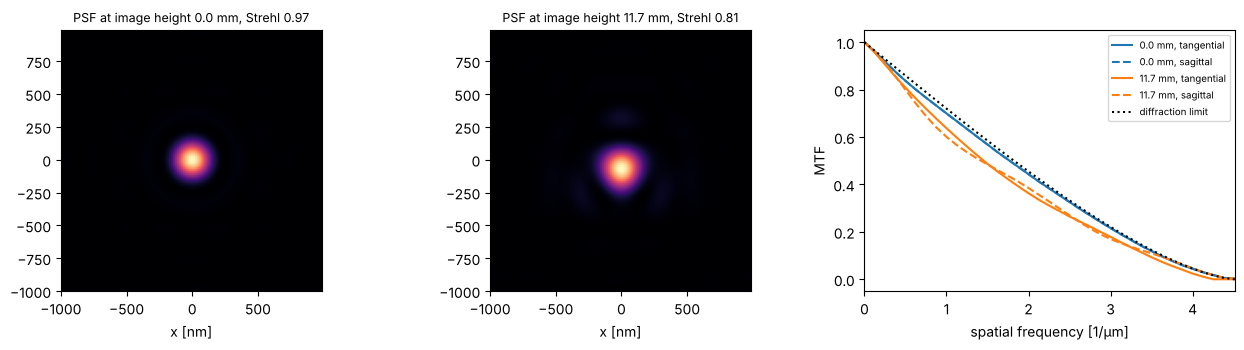

In [22]:
x = grid1d(-0.001, 0.001, 128)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for j, h in enumerate([0.0, 46.8]):
    psf = np.abs(litho.psf(x, x, h, N=48))**2
    axes[j].imshow(psf, extent=1e6*np.array([x[0], x[-1], x[0], x[-1]]), origin="lower", cmap="magma")
    axes[j].set_title("PSF at image height {:.1f} mm, Strehl {:.2f}".format(h/4, litho.strehl(h, 48)), fontsize=9)
    axes[j].set_xlabel("x [nm]")
x = grid1d(-0.004, 0.004, 256)
fx = np.fft.fftshift(np.fft.fftfreq(len(x), x[1] - x[0]))
c = len(x)//2
NA_l = litho.pupil(0.0, 33).NA
for j, h in enumerate([0.0, 46.8]):
    mtf = litho.mtf(x, x, h, N=48)
    axes[2].plot(1e-3*fx[c:], mtf[c:, c], "C{}".format(j), label="{:.1f} mm, tangential".format(h/4))
    axes[2].plot(1e-3*fx[c:], mtf[c, c:], "C{}--".format(j), label="{:.1f} mm, sagittal".format(h/4))
nu = np.clip(fx[c:]/(2*NA_l/WL_KrF), 0, 1)
axes[2].plot(1e-3*fx[c:], 2/np.pi*(np.arccos(nu) - nu*np.sqrt(1 - nu**2)), "k:", label="diffraction limit")
axes[2].set_xlim(0, 1e-3*2*NA_l/WL_KrF)
axes[2].set_xlabel("spatial frequency [1/µm]")
axes[2].set_ylabel("MTF")
axes[2].legend(fontsize=7)
plt.tight_layout()

### Why KrF lasers are line-narrowed

With a single glass the lens cannot be colour corrected. The focus moves by about a quarter of a micrometre per
picometre of wavelength, while the depth of focus is ±λ/(2NA²) ≈ ±0.4 µm. Unnarrowed KrF lasers emit about
300 pm wide, so lithography lasers are narrowed to below 1 pm FWHM. The Strehl ratio on axis, at a fixed image
plane, drops within a few pm.

axial colour: 0.241 µm/pm


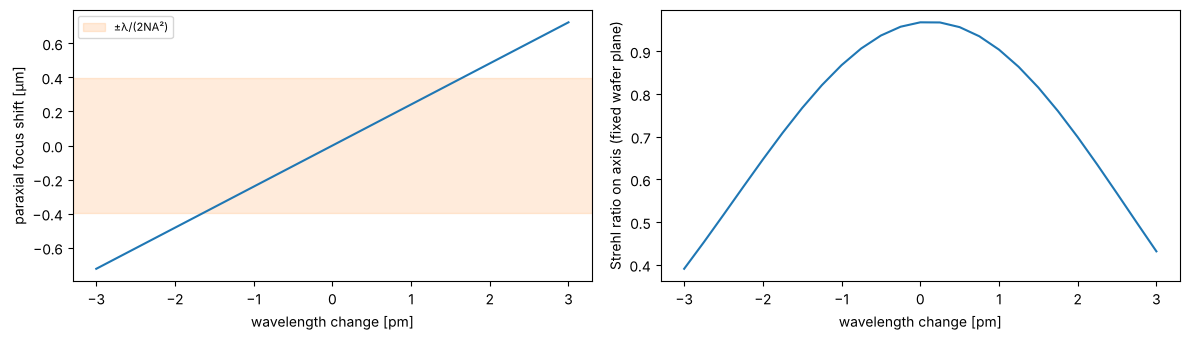

In [23]:
dl = np.linspace(-3, 3, 25)*1e-9           # pm in mm
d0 = litho.surfaces[-1].thickness
focus = np.array([litho.with_wavelength(WL_KrF + d).paraxial().image_distance for d in dl]) - d0
strehl = [litho.with_wavelength(WL_KrF + d).strehl(0.0, 33) for d in dl]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(1e9*dl, 1e3*focus)
axes[0].axhspan(-1e3*WL_KrF/(2*NA_l**2), 1e3*WL_KrF/(2*NA_l**2), color="C1", alpha=0.15, label="±λ/(2NA²)")
axes[0].set_xlabel("wavelength change [pm]")
axes[0].set_ylabel("paraxial focus shift [µm]")
axes[0].legend(fontsize=8)
axes[1].plot(1e9*dl, strehl)
axes[1].set_xlabel("wavelength change [pm]")
axes[1].set_ylabel("Strehl ratio on axis (fixed wafer plane)")
plt.tight_layout()
print("axial colour: {:.3f} µm/pm".format(1e3*np.polyfit(1e9*dl, focus, 1)[0]))

### Decentre sensitivity of the elements

Tolerancing is a direct application of decentred surfaces. Each of the 21 elements is decentred by 1 µm in y
(both surfaces), and the coma Z8 on axis that results is computed. The elements of the second waist and the
large elements around the stop (elements 12 to 17) are the most sensitive. The elements next to the reticle
hardly matter for an on-axis point.

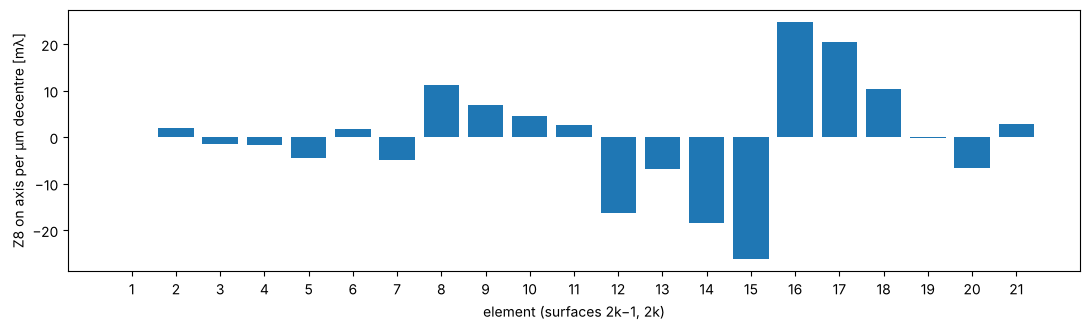

In [24]:
elements = [(i, i + 1) for i in range(0, 42, 2)]
coma = []
base = litho.zernike(0.0, 9, N=33)[7]
for i, j in elements:
    s = litho.copy().surfaces
    for k in (i, j):
        s[k].decenter = (0.0, 1e-3)
    coma.append(rt.System(s, litho.stop_index, WL_KrF, object_distance=litho.object_distance,
                          object_height=46.8).zernike(0.0, 9, N=33)[7] - base)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(np.arange(1, 22), 1e3*np.array(coma))
ax.set_xticks(np.arange(1, 22))
ax.set_xlabel("element (surfaces 2k−1, 2k)")
ax.set_ylabel("Z8 on axis per µm decentre [mλ]")
plt.tight_layout()

### Axial (z) shift sensitivity of the elements

`System.with_axial_shift(first, last, dz)` moves the surfaces `first…last` along the axis while the reticle,
the other elements and the wafer stay put. Shifting each element by ±1 µm and taking central differences
gives three sensitivities: the shift of the paraxial focus relative to the fixed wafer plane, the change of
the on-axis spherical aberration Z9, and the change of the image height at the field edge (a magnification
error). In a scanner, focus is taken up by the wafer stage and magnification by the reticle stage or by
dedicated manipulator elements, so the spherical aberration is what remains. Element 14 next to the stop is
the most critical for focus and spherical aberration (about 0.9 µm focus and 30 mλ Z9 per µm), elements 6 and 7
in the first waist dominate the magnification. Elements with opposite signs (e.g. 14 and 16) are natural
compensator pairs.

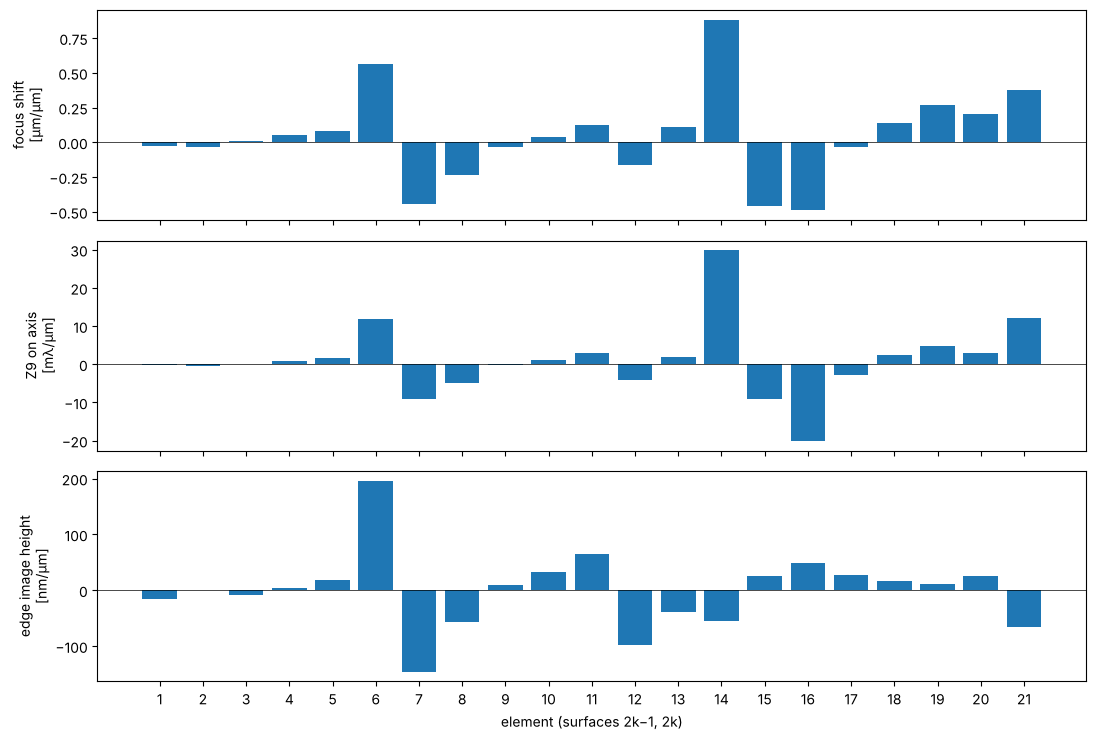

In [25]:
def focus_offset(s):
    # paraxial focus relative to the (fixed) image plane
    return s.paraxial().image_distance - s.surfaces[-1].thickness

def observables(s):
    return np.array([focus_offset(s), s.zernike(0.0, 9, N=33)[8], s.trace_pupil(46.8).points[-1, 0, 1]])

dz = 1e-3
sens = np.array([(observables(litho.with_axial_shift(i, j, dz))
                  - observables(litho.with_axial_shift(i, j, -dz)))/(2*dz) for i, j in elements])

fig, axs = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
k = np.arange(1, 22)
axs[0].bar(k, sens[:, 0])
axs[0].set_ylabel("focus shift\n[µm/µm]")
axs[1].bar(k, sens[:, 1])     # Z9 in waves per mm = mλ per µm
axs[1].set_ylabel("Z9 on axis\n[mλ/µm]")
axs[2].bar(k, 1e3*sens[:, 2])  # mm/mm -> nm/µm
axs[2].set_ylabel("edge image height\n[nm/µm]")
axs[2].set_xticks(k)
axs[2].set_xlabel("element (surfaces 2k−1, 2k)")
for ax in axs:
    ax.axhline(0, color="k", lw=0.5)
plt.tight_layout()

## 7 An ArF immersion lens: NA 1.35

The lithography notebooks on hyper-NA imaging and polarization (27, 31, 34)
use a second published design, the dioptric water immersion lens of Zeiss
patent US 7,187,503 B2 (second embodiment, `raytrace.zeiss_arfi_lens()`):
193.368 nm, NA 1.35 in water, 8x reduction, image field Ø 14 mm, all fused
silica in helium, 11 even aspheres, 1 mm of water between the last lens and
the wafer. The aperture stop sits in the second belly, on a plane surface
with a negative thickness. The rays in the water reach 65° from the axis,
and the strong pupil aberration of such a lens is why the ray aiming falls
back to a continuation from the chief ray for the rim rays.

NA = 1.3499, magnification = -0.12500, reticle to wafer = 960.2 mm, water gap 1.000 mm


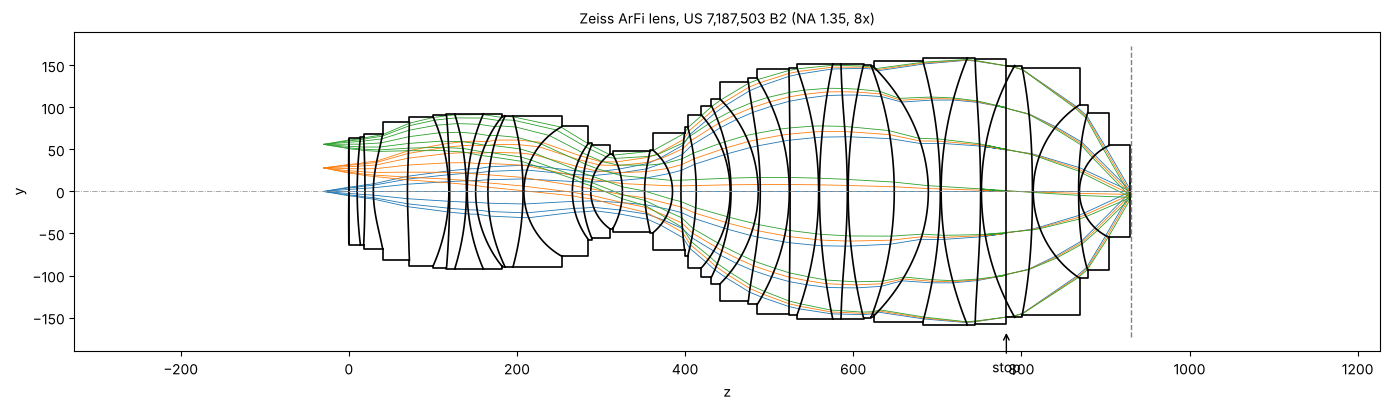

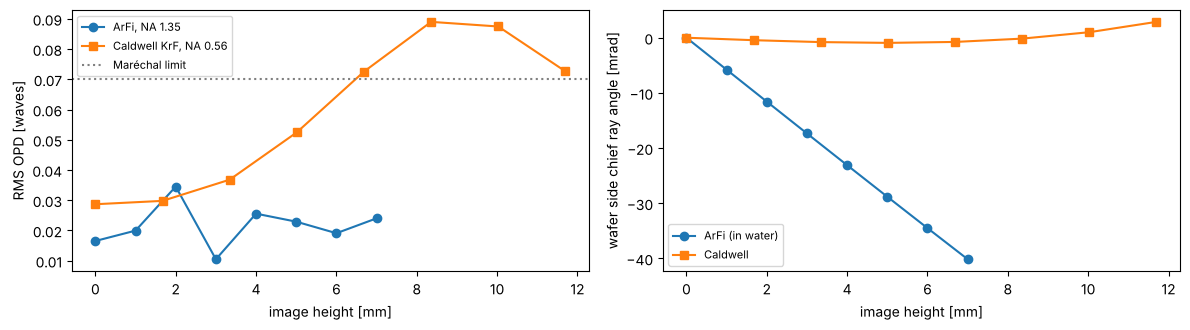

In [26]:
arfi = rt.zeiss_arfi_lens()
p_arfi = arfi.paraxial()
print("NA = {:.4f}, magnification = {:.5f}, reticle to wafer = {:.1f} mm, water gap {:.3f} mm".format(
    arfi.pupil(0.0, 33).NA, p_arfi.magnification, arfi.object_distance + arfi.image_z,
    arfi.surfaces[-1].thickness))

fig, ax = plt.subplots(figsize=(14, 4.2))
arfi.draw(ax, fields=[0.0, 28.0, 56.0], n_rays=7, lw=0.6)
z_stop = arfi.vertex_z[arfi.stop_index]
ax.annotate("stop", (z_stop, -165), (z_stop, -215), ha="center", arrowprops=dict(arrowstyle="->"))
ax.set_title("Zeiss ArFi lens, US 7,187,503 B2 (NA 1.35, 8x)", fontsize=10)
plt.tight_layout()

hs = np.linspace(0, 56.0, 8)
rms = [arfi.rms_opd(h, 33) for h in hs]
chief = [arfi.trace_pupil(h) for h in hs]
tele = [1e3*c.directions[-1, 0, 1] for c in chief]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(hs/8, rms, "o-", label="ArFi, NA 1.35")
axes[0].plot(np.linspace(0, 46.8, 8)/4, [litho.rms_opd(h, 33) for h in np.linspace(0, 46.8, 8)], "s-",
             label="Caldwell KrF, NA 0.56")
axes[0].axhline(0.07, color="0.5", ls=":", label="Maréchal limit")
axes[0].set_xlabel("image height [mm]"), axes[0].set_ylabel("RMS OPD [waves]"), axes[0].legend(fontsize=8)
axes[1].plot(hs/8, tele, "o-", label="ArFi (in water)")
axes[1].plot(np.linspace(0, 46.8, 8)/4, [1e3*litho.trace_pupil(h).directions[-1, 0, 1] for h in np.linspace(0, 46.8, 8)],
             "s-", label="Caldwell")
axes[1].set_xlabel("image height [mm]"), axes[1].set_ylabel("wafer side chief ray angle [mrad]")
axes[1].legend(fontsize=8)
plt.tight_layout()

The immersion lens is better corrected than Caldwell's (about 0.02 waves
RMS over the whole field, at more than twice the NA and a shorter
wavelength), but it is not telecentric on the wafer side: its chief ray
leaves the last lens at up to 40 mrad, where Caldwell's stays within 3 mrad.
Notebook 27 shows what this does to placement through focus.

## Summary

| Task | API |
|---|---|
| surfaces | `Surface(R, thickness, n_after=…, material=(n_d, V_d), conic=…, aspheric=(A4, A6, …), semi_diameter=…, mirror=…, decenter=…, tilt=…)`, `IdealLens(f, thickness)`, `CoordinateBreak(decenter, tilt, thickness)` |
| system | `System(surfaces, stop_index, wavelength, object_distance=np.inf, field_angle=…, entrance_pupil_radius=…, image_tilt=…)`, `frames()`, `to_image_frame()` |
| examples | `caldwell_krf_lens()`, `zeiss_arfi_lens()`, `fused_silica()`, `fused_silica_arf()` |
| variants | `copy()`, `with_wavelength()`, `with_image_distance()`, `at_paraxial_focus()`, `with_axial_shift()` |
| paraxial | `paraxial()` (EFL, BFL, pupils, NA, F/#, marginal and chief rays), `abcd_matrix()`, `to_abcd()`, `seidel()` |
| real rays | `rays()`, `trace()`, `trace_pupil()`, `spot_diagram()`, `ray_fan()`, `draw()`, `plot_spot_diagram()`, `plot_ray_fan()` |
| wavefront | `opd()`, `zernike()`, `rms_opd()`, `strehl()` |
| wave optics | `pupil()` → `imaging`, `psf()`, `mtf()` |